# Experiment 8: controlled decoder-only repair training

**Question:** does training the final decoder to reconstruct normal images from repaired codes add useful anomaly-detection performance beyond our successful inference-only repair?

This is one fixed, controlled pilot, not a hyperparameter search. It may succeed, do nothing, or teach the decoder to undo the useful anomaly effect. The outputs distinguish these possibilities.

## What was trained before?

The earlier reset-only implementation enabled the whole autoencoder with `base.requires_grad_(True)` and excluded codebook embeddings from gradient optimization because their updates used EMA. Its encoder and decoder parameters were therefore trainable; it was not encoder-only. The uploaded original QMem training notebook used `Adam(model.parameters(), ...)`. The context-prior experiments trained a separate predictor while freezing the autoencoder. Experiments 6–7 unigram repair did not train neural weights.

This experiment specifically trains **only a copy of `decoder_final`**. The encoders, `pre_quant_bottom`, both quantizers including EMA buffers, and `decoder_top` remain frozen. Decoder-top is frozen because it also contributes to the bottom-code encoding path; changing it would change the distribution being tested.

## Established result and current hypothesis

Experiment 7 selected alpha=0.25 using normal images. Bounded repair improved primary mean-frame IoU from 0.34194 to 0.35032, historical IoU from 0.35509 to 0.35924, and AP from 0.46006 to 0.48437. Independent normal MAE increased 2.41%. Achieved normal-audit FPR changed from 2.10% to 2.30%, so equal actual-FPR superiority is not established.

We keep the same normal unigram table, 99th-percentile rarity gate and alpha=0.25. We ask whether a decoder can tolerate this code intervention on normal images without losing anomaly separation. **The encoder is not being taught a new distribution in this experiment.**

## Two matched training arms

Both start from the exact original T1 QMem v1 decoder, use the same normal training images in the same order, and receive three epochs with Adam at 1e-5. Smoke mode uses one epoch and a tiny image subset.

- **Ordinary fine-tuning control:** MSE reconstruction from original codes.
- **Repair fine-tuning:** `[MSE(original-code reconstruction, x) + 0.5 * MSE(full-repair reconstruction, x)] / 1.5`.

Normalizing the weights prevents merely multiplying the overall loss magnitude. Lambda=0.5 is a prespecified pilot choice, not an optimized value. Both branches use the same decoder parameters. Training uses normal targets only; no anomaly labels, synthetic anomalies, QMem temporal loss, reset, or context predictor are introduced.

The QMem temporal training is already embodied in the frozen upstream checkpoint. This is a second-stage decoder adaptation experiment, not a repetition of the original end-to-end QMem objective. An encoder-only temporal term cannot update a frozen encoder or provide a decoder gradient.

At inference we compare **plain reconstruction** and **bounded repair** for each arm:

`bounded = 0.75 * decode(original codes) + 0.25 * decode(repaired codes)`

Absolute RGB reconstruction error is taken AFTER the blend, followed by the same smoothing and morphology as previous runs. Alpha and training lambda have different purposes; neither is selected on test results.

## Checkpoint selection, fixed in advance

Both training arms use the same selection rule: minimum normal-selection **bounded reconstruction MAE**, provided ordinary reconstruction MAE is no more than 5% above the original QMem value. Epoch zero is eligible; strict improvement is required, with earliest ties retained. Both arms still receive the full identical training budget. Selected epochs can differ.

This rewards normal reconstruction only and does not guarantee anomaly improvements. The independent normal audit and test never change the chosen checkpoint. We deliberately do not select one checkpoint per inference mode: each arm uses one selected decoder for both plain and bounded evaluation.

## Seven evaluation streams

| Stream | Decoder | Inference |
|---|---|---|
| Christian | Original Christian | Plain |
| Frozen QMem | Original QMem | Plain |
| Frozen QMem + repair | Original QMem | Bounded repair, alpha .25 |
| Ordinary FT / plain | Ordinary fine-tuned | Plain |
| Ordinary FT / repair | Ordinary fine-tuned | Bounded repair |
| Repair FT / plain | Repair-trained | Plain |
| Repair FT / repair | Repair-trained | Bounded repair |

**Primary causal comparison:** repair FT / repair minus ordinary FT / repair.

**Practical comparison:** repair FT / repair minus frozen QMem + repair. A gain only over un-repaired original QMem is insufficient to establish a benefit from training.

Primary endpoint remains mean-frame postprocessed IoU at normal calibration target FPR .02, accompanied by achieved independent normal-audit FPR. Historical Tukey IoU, full-pixel AP/AUROC and the fixed FPR curve are secondary. No test-set threshold optimization or claim of exact matched achieved FPR is made.

## Kaggle inputs

1. Import this notebook and enable a GPU. Standard Kaggle packages are used; no pip installation is needed.
2. Attach the original normal data: `training/after/<video>/<image>` and `validation/after/<video>/<image>`, preferably the original with-background version.
3. Attach test images and matching masks: `images/before/<video>/<image>` and `masks/before/<video>/<image>`.
4. Enable Kaggle Internet for pinned, SHA-256 verified Christian and original T1 QMem v1 weights, OR attach both original `.pth` files. A previous output ZIP containing those original checkpoints also works. Reset, v2, context, or newly trained weights are not substitutes.
5. If automatic path discovery is ambiguous, fill the four directory overrides and/or `CHECKPOINT_PATHS` in Block 1. Do not guess path names.

No Experiment 7 report, cached `.npy`, trained context model or large saved score maps are needed. The fixed alpha of .25 comes from the previously completed normal-only selection. Counts and the rarity gate are recomputed from the same data.

Run all blocks with `SMOKE=True`, check completion, then set `SMOKE=False`, restart the session and Run All. Full counts must be train 3829, select 521, calibrate 128, audit 234, test 496. Count mismatches should be investigated, not bypassed by disabling checks.

Bottom and top IDs are cached once, avoiding repeated encoder computation during training. Only compact decoder checkpoints are saved for the trained arms. Full-pixel AP/AUROC still takes time and several GB of temporary score-map storage. Use a GPU for the full run; reduce TRAIN_BATCH and BATCH together if memory is insufficient, recording that change.


## 1. Configuration and original weights

Fixes the training budget, repair loss weight, inference alpha, thresholds and paths. Loads only the intended original checkpoints after SHA-256 verification. Three epochs and one seed are a limited mechanism test, not a claim of optimal training.

In [1]:
# Block 1: configuration and verified original reference checkpoints.
import os, sys, json, math, random, hashlib, re, time, uuid, zipfile, shutil, urllib.request, gc
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import (
    gaussian_filter,
    binary_closing,
    binary_opening,
    binary_fill_holes,
    generate_binary_structure,
    label,
)
from sklearn.metrics import roc_auc_score, average_precision_score
from tqdm.auto import tqdm

SMOKE = False  # Run once, then set False and Run All for the full experiment.
SEED = 1337
SIZE = 256
BATCH = 4
WORKERS = 0
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/qmem_experiment8")
DATASET_ROOT = ""
TRAIN_AFTER_PATH = ""
VAL_AFTER_PATH = ""
TEST_BEFORE_PATH = ""
TEST_MASK_PATH = ""
# Optional exact paths. Otherwise search attached files/ZIPs by expected SHA-256.
CHECKPOINT_PATHS = {"christian": "", "qmem_v1": ""}
# If checkpoints are not attached, download small files from a pinned GitHub commit.
# Requires Kaggle Internet ON. Set False for a fully offline run with both reference checkpoints attached.
ALLOW_PINNED_DOWNLOAD = True
FPR_TARGETS = (0.005, 0.01, 0.02, 0.05, 0.10)
VISUAL_FPR = 0.02  # Fixed before viewing results; not selected by test IoU.
CAL_SAMPLE_PIXELS = 4096

BOOTSTRAP_REPEATS = 2000
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu" and not SMOKE:
    raise RuntimeError("Enable a Kaggle GPU for the full run.")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.set_num_threads(min(4, os.cpu_count() or 1))
RUN_DIR = OUTPUT_ROOT / (
    time.strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:6] + ("_SMOKE" if SMOKE else "")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Device:", DEVICE, "PyTorch:", torch.__version__, "SMOKE:", SMOKE, "\nOutputs:", RUN_DIR)
SPECS = {
    "christian": dict(
        hash="18d0628f3dacc0739d604465aa64961d6a889c8f05f6a863048efffddc8520a0",
        suffix="Baseline_christian/Code/proposed_solution/checkpoint/model.pth",
    ),
    "qmem_v1": dict(
        hash="5e5e43d4b8151ce2fa3919f10a96ac32287b657c8a9556d1260be3ff457162e9",
        suffix="checkpoints/strict_qmem_v1_reference_T1K2_lambda0p05/best.pth",
    ),
    "qmem_v2_full": dict(
        hash="090c5ed737e4ce5b55bab282f067eb6f47fa910a37ea736a28a279733483fa35",
        suffix="checkpoints/strict_qmem_v2_T2K2_full/best.pth",
    ),
}
SPECS.pop("qmem_v2_full")
COMMIT = "ba0b971b86fab7a9c53df4b09847b925c2cee262"


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1024 * 1024), b""):
            h.update(b)
    return h.hexdigest()


def natural(p):
    return [int(s) if s.isdigit() else s.lower() for s in re.split(r"(\d+)", str(p))]


def images(root):
    return sorted(
        [p for p in Path(root).rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}],
        key=natural,
    )


def unique(paths, description):
    p = sorted(set(Path(x).resolve() for x in paths))
    if len(p) != 1:
        raise RuntimeError(
            f"{description}: found {len(p)} possibilities: {p}. Set explicit paths in Block 1."
        )
    return p[0]


# Search only appropriately named, small checkpoint files; hash each file at most once.
file_hash = {}
checkpoint_files = {}
for name, path in CHECKPOINT_PATHS.items():
    if path:
        p = Path(path)
        if sha256(p) != SPECS[name]["hash"]:
            raise RuntimeError(f"Wrong checkpoint for {name}: hash mismatch.")
        checkpoint_files[name] = p
for p in sorted(INPUT_ROOT.rglob("*.pth")):
    if len(checkpoint_files) == len(SPECS):
        break
    if p.stat().st_size > 30 * 1024**2:
        continue
    digest = sha256(p)
    file_hash[str(p)] = digest
    for name, spec in SPECS.items():
        if digest == spec["hash"] and name not in checkpoint_files:
            checkpoint_files[name] = p
ckdir = RUN_DIR / "input_checkpoints"
ckdir.mkdir()
# Supports your old strict_bottom_code_campa_v2_outputs.zip or a repository ZIP.
for zp in sorted(INPUT_ROOT.rglob("*.zip")):
    if len(checkpoint_files) == len(SPECS):
        break
    try:
        with zipfile.ZipFile(zp) as z:
            for name, spec in SPECS.items():
                if name in checkpoint_files:
                    continue
                candidates = [
                    i
                    for i in z.infolist()
                    if not i.filename.startswith("__MACOSX/")
                    and i.filename.lower().endswith(".pth")
                    and i.file_size < 30 * 1024**2
                ]
                for item in candidates:
                    data = z.read(item)
                    if hashlib.sha256(data).hexdigest() == spec["hash"]:
                        dst = ckdir / (name + ".pth")
                        dst.write_bytes(data)
                        checkpoint_files[name] = dst
                        break
    except zipfile.BadZipFile:
        continue
for name, spec in SPECS.items():
    if name in checkpoint_files:
        continue
    if not ALLOW_PINNED_DOWNLOAD:
        raise FileNotFoundError(f"Attach checkpoint for {name}; see setup instructions.")
    url = f'https://raw.githubusercontent.com/Shuvro-Ahmed/Anamoly-waste-extension-polimi/{COMMIT}/{spec["suffix"]}'
    dst = ckdir / (name + ".pth")
    print("Downloading pinned checkpoint:", name)
    try:
        with urllib.request.urlopen(url, timeout=60) as r, open(dst, "wb") as f:
            shutil.copyfileobj(r, f)
    except Exception as exc:
        raise RuntimeError(
            f"Cannot obtain {name}. Enable Kaggle Internet or attach the checkpoint and rerun. {exc}"
        ) from exc
    if sha256(dst) != spec["hash"]:
        raise RuntimeError(f"Downloaded {name} failed SHA-256 verification.")
    checkpoint_files[name] = dst
assert len(checkpoint_files) == len(SPECS)
print("Reference checkpoint hashes verified:", {k: str(v) for k, v in checkpoint_files.items()})



# Fixed before this training experiment; alpha was chosen by Experiment 7 normal selection.
ALPHA=0.25
REPAIR_SELECT_TAIL=0.01
NORMAL_MAE_BUDGET=0.05
PRIMARY_FPR=0.02
EPOCHS=1 if SMOKE else 3
DECODER_LR=1e-5
REPAIR_LAMBDA=0.5
TRAIN_BATCH=4
EXPECTED_COUNTS=dict(train=3829,select=521,calibrate=128,audit=234,test=496)
CHECK_EXPECTED_COUNTS=True
SAVE_RAW_MAPS=False
CACHE_DIR=RUN_DIR/'cache';CACHE_DIR.mkdir()
import copy


Device: cuda PyTorch: 2.10.0+cu128 SMOKE: False 
Outputs: /kaggle/working/qmem_experiment8/20260921_202543_2328f4
Reference checkpoint hashes verified: {'christian': '/kaggle/working/qmem_experiment8/20260921_202543_2328f4/input_checkpoints/christian.pth', 'qmem_v1': '/kaggle/working/qmem_experiment8/20260921_202543_2328f4/input_checkpoints/qmem_v1.pth'}


## 2. Faithful architecture and frozen extraction

Loads the exact VQ-VAE-2 architecture and verifies latent extraction against its original forward path. Keeps codebook EMA in evaluation mode. Do not call base.train(): the full base must remain frozen throughout this notebook.

In [2]:
# Block 2: exact architecture and non-mutating feature extraction.
import torch
import torch.nn as nn
import torch.nn.functional as funct


class VectorQuantizerEMA(nn.Module):

    def __init__(
        self, num_embeddings=64, embedding_dim=64, decay=0.99, epsilon=1e-05, commitment_cost=0.25
    ):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        self.decay = decay
        self.epsilon = epsilon
        self.commitment_cost = commitment_cost
        self.embedding = nn.Parameter(torch.empty(self.num_embeddings, self.embedding_dim))
        self.register_buffer("cluster_size", torch.zeros(self.num_embeddings))
        self.register_buffer("ema_w", torch.empty(self.num_embeddings, self.embedding_dim))
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.uniform_(self.embedding, -1.0 / self.num_embeddings, 1.0 / self.num_embeddings)
        self.ema_w.data.copy_(self.embedding.data)
        self.cluster_size.zero_()

    def forward(self, z):
        z_perm = z.permute(0, 2, 3, 1).contiguous()
        z_flat = z_perm.view(-1, self.embedding_dim)
        emb = self.embedding
        z_sq = (z_flat**2).sum(dim=1, keepdim=True)
        emb_sq = (emb**2).sum(dim=1)
        distances = z_sq - 2 * (z_flat @ emb.t()) + emb_sq.unsqueeze(0)
        encoding_indices = torch.argmin(distances, dim=1)
        encodings = funct.one_hot(encoding_indices, self.num_embeddings).type(z_flat.dtype)
        z_q_flat = encodings @ emb
        z_q = z_q_flat.view(z_perm.shape).permute(0, 3, 1, 2).contiguous()
        if self.training:
            cluster_size = encodings.sum(dim=0)
            self.cluster_size.data.mul_(self.decay).add_(cluster_size, alpha=1 - self.decay)
            embed_sum = encodings.t() @ z_flat
            self.ema_w.data.mul_(self.decay).add_(embed_sum, alpha=1 - self.decay)
            n = self.cluster_size.sum()
            cluster_size_normalized = (
                (self.cluster_size + self.epsilon) / (n + self.num_embeddings * self.epsilon) * n
            )
            cluster_size_normalized = torch.clamp(cluster_size_normalized, min=self.epsilon)
            updated_emb = self.ema_w / cluster_size_normalized.unsqueeze(1)
            self.embedding.data.copy_(updated_emb)
        z_q_st = z + (z_q - z).detach()
        commitment_loss = self.commitment_cost * funct.mse_loss(z_q.detach(), z)
        avg_probs = encodings.mean(dim=0)
        perplexity = torch.exp(-(avg_probs * torch.log(avg_probs + 1e-10)).sum())
        return (z_q_st, commitment_loss, perplexity)


class ResidualBlock(nn.Module):

    def __init__(self, channels, groups=8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=1),
            nn.GroupNorm(groups, channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=1),
            nn.GroupNorm(groups, channels),
        )

    def forward(self, x):
        return funct.relu(x + self.net(x))


class Encoder(nn.Module):

    def __init__(self, in_channels, hidden_channels, embedding_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, hidden_channels, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, hidden_channels, 4, 2, 1),
            nn.ReLU(inplace=True),
            ResidualBlock(hidden_channels),
            nn.Conv2d(hidden_channels, embedding_dim, kernel_size=3, stride=1, padding=1),
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):

    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.net = nn.Sequential(
            ResidualBlock(in_channels),
            nn.ConvTranspose2d(in_channels, hidden_channels, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(hidden_channels, hidden_channels // 2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels // 2, out_channels, 3, 1, 1),
        )

    def forward(self, x):
        return self.net(x)


class VQVAE2(nn.Module):

    def __init__(
        self,
        in_channels=3,
        hidden_channels=128,
        embedding_dim=64,
        num_embeddings=1024,
        decay=0.99,
        commitment_cost=0.25,
    ):
        super().__init__()
        self.encoder_bottom = Encoder(in_channels, hidden_channels, embedding_dim)
        self.encoder_top = Encoder(embedding_dim, hidden_channels, embedding_dim)
        self.quantizer_top = VectorQuantizerEMA(
            num_embeddings, embedding_dim, decay=decay, commitment_cost=commitment_cost
        )
        self.quantizer_bottom = VectorQuantizerEMA(
            num_embeddings, embedding_dim, decay=decay, commitment_cost=commitment_cost
        )
        self.pre_quant_bottom = nn.Conv2d(embedding_dim * 2, embedding_dim, kernel_size=1)
        self.decoder_top = Decoder(embedding_dim, hidden_channels, embedding_dim)
        self.decoder_final = Decoder(embedding_dim * 2, hidden_channels, out_channels=in_channels)

    def forward(self, x):
        z_bottom = self.encoder_bottom(x)
        z_top = self.encoder_top(z_bottom)
        z_q_top, q_loss_top, perplexity_top = self.quantizer_top(z_top)
        dec_top = self.decoder_top(z_q_top)
        if dec_top.shape[2:] != z_bottom.shape[2:]:
            dec_top = funct.interpolate(dec_top, size=z_bottom.shape[2:], mode="nearest")
        z_bottom_combined = torch.cat([z_bottom, dec_top], dim=1)
        z_bottom_combined = self.pre_quant_bottom(z_bottom_combined)
        z_q_bottom, q_loss_bottom, perplexity_bottom = self.quantizer_bottom(z_bottom_combined)
        top_for_decode = dec_top
        if top_for_decode.shape[2:] != z_q_bottom.shape[2:]:
            top_for_decode = funct.interpolate(
                top_for_decode, size=z_q_bottom.shape[2:], mode="nearest"
            )
        z_combined = torch.cat([z_q_bottom, top_for_decode], dim=1)
        recon = self.decoder_final(z_combined)
        recon = torch.sigmoid(recon)
        vq_loss = q_loss_top + q_loss_bottom
        return (recon, vq_loss)


def fingerprint(model):
    h = hashlib.sha256()
    for k, v in sorted(model.state_dict().items()):
        h.update(k.encode())
        h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


def load_model(name):
    saved = torch.load(checkpoint_files[name], map_location="cpu", weights_only=True)
    state = saved.get("model_state_dict", saved.get("state_dict", saved))
    model = VQVAE2().to(DEVICE)
    model.load_state_dict({k.removeprefix("module."): v for k, v in state.items()}, strict=True)
    model.eval().requires_grad_(False)
    return model


@torch.no_grad()
def qlookup(z, q, margin=False):
    d = q.embedding_dim
    b, c, h, w = z.shape
    flat = z.permute(0, 2, 3, 1).reshape(-1, d)
    e = q.embedding
    dist = (
        flat.square().sum(1, keepdim=True) - 2 * flat @ e.T + e.square().sum(1)[None]
    ).clamp_min(0)
    ids = dist.argmin(1).view(b, h, w)
    vectors = F.embedding(ids, e).permute(0, 3, 1, 2).contiguous()
    gap = None
    if margin:
        best = dist.topk(2, dim=1, largest=False).values
        gap = ((best[:, 1] - best[:, 0]) / (best[:, 1] + 1e-8)).view(b, h, w)
    return vectors, ids, gap


@torch.no_grad()
def expose(model, x):
    assert not model.training
    b = model.encoder_bottom(x)
    t = model.encoder_top(b)
    qt, it, gap = qlookup(t, model.quantizer_top, True)
    tc = model.decoder_top(qt)
    if tc.shape[-2:] != b.shape[-2:]:
        tc = F.interpolate(tc, size=b.shape[-2:], mode="nearest")
    h = model.pre_quant_bottom(torch.cat([b, tc], 1))
    qb, ib, _ = qlookup(h, model.quantizer_bottom)
    rec = torch.sigmoid(model.decoder_final(torch.cat([qb, tc], 1)))
    return dict(
        bottom_continuous=b,
        top_continuous=t,
        top_quantized=qt,
        top_context=tc,
        top_ids=it,
        bottom_ids=ib,
        bottom_quantized=qb,
        top_margin=gap,
        recon=rec,
    )


forward_checks = []
module_changes = []
reference = load_model("christian")
ref_state = {k: v.detach().cpu().clone() for k, v in reference.state_dict().items()}
del reference
for name in SPECS:
    model = load_model(name)
    before = fingerprint(model)
    with torch.no_grad():
        torch.manual_seed(SEED)
        x = torch.rand(2, 3, SIZE, SIZE, device=DEVICE)
        ref, _ = model(x)
        out = expose(model, x)
        err = float((ref - out["recon"]).abs().max())
    assert err < 2e-6, ("Forward differs", name, err)
    assert fingerprint(model) == before
    forward_checks.append(dict(model=name, max_forward_error=err))
    # Parameter drift says what changed, not whether that change caused collapse.
    for prefix in [
        "encoder_top",
        "quantizer_top",
        "decoder_top",
        "encoder_bottom",
        "quantizer_bottom",
    ]:
        numerator = denominator = 0.0
        for k, v in model.state_dict().items():
            if k.startswith(prefix + "."):
                a = v.detach().cpu().double()
                r = ref_state[k].double()
                numerator += float((a - r).square().sum())
                denominator += float(r.square().sum())
        module_changes.append(
            dict(
                model=name,
                module=prefix,
                relative_l2_change_vs_christian=math.sqrt(numerator / max(denominator, 1e-30)),
            )
        )
    del model, x, ref, out
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
pd.DataFrame(forward_checks).to_csv(RUN_DIR / "forward_checks.csv", index=False)
pd.DataFrame(module_changes).to_csv(RUN_DIR / "module_changes.csv", index=False)
print(pd.DataFrame(forward_checks).to_string(index=False))
del ref_state


    model  max_forward_error
christian       1.788139e-07
  qmem_v1       2.384186e-07


## 3. Input discovery and video-separated roles

Train fits the frequency table and decoder; normal select chooses checkpoints and fixes the rarity gate; normal calibrate fixes thresholds; normal audit checks damage and false alarms; test measures detection. Exact image-duplicate checks do not establish independence between acquisition sessions.

In [3]:
# Block 3: same data split as experiment 1; no parameter selection on test labels.
root = Path(DATASET_ROOT) if DATASET_ROOT else INPUT_ROOT
if TRAIN_AFTER_PATH or VAL_AFTER_PATH:
    if not (TRAIN_AFTER_PATH and VAL_AFTER_PATH):
        raise ValueError("Set both train and validation overrides.")
    TRAIN_ROOT = Path(TRAIN_AFTER_PATH)
    VAL_ROOT = Path(VAL_AFTER_PATH)
else:
    candidates = [
        p.parent.parent
        for p in root.rglob("after")
        if p.parent.name == "training" and (p.parent.parent / "validation/after").is_dir()
    ]
    preferred = [p for p in candidates if "with_background" in str(p).lower()]
    tv = unique(preferred or candidates, "Training/validation root")
    TRAIN_ROOT = tv / "training/after"
    VAL_ROOT = tv / "validation/after"
if TEST_BEFORE_PATH or TEST_MASK_PATH:
    if not (TEST_BEFORE_PATH and TEST_MASK_PATH):
        raise ValueError("Set both test image and mask overrides.")
    BEFORE_ROOT = Path(TEST_BEFORE_PATH)
    MASK_ROOT = Path(TEST_MASK_PATH)
else:
    candidates = [
        p.parent.parent
        for p in root.rglob("before")
        if p.parent.name == "images" and (p.parent.parent / "masks/before").is_dir()
    ]
    tr = unique(candidates, "Test root")
    BEFORE_ROOT = tr / "images/before"
    MASK_ROOT = tr / "masks/before"


def records(root):
    rs = []
    for p in images(root):
        rel = p.relative_to(root)
        if len(rel.parts) < 2:
            raise ValueError(f"Expected video folders: {p}")
        rs.append(dict(path=str(p), video=rel.parts[0], relative=str(rel)))
    if not rs:
        raise ValueError(f"No images: {root}")
    return rs


train = records(TRAIN_ROOT)
val = records(VAL_ROOT)
test = records(BEFORE_ROOT)
vids = sorted({r["video"] for r in val})
np.random.default_rng(SEED).shuffle(vids)
if len(vids) < 3:
    raise ValueError("Need at least three validation videos.")
a = max(1, len(vids) // 2)
b = max(1, (len(vids) - a) // 2)
groups = {"select": set(vids[:a]), "calibrate": set(vids[a : a + b]), "audit": set(vids[a + b :])}
splits = {
    "train": train,
    **{k: [r for r in val if r["video"] in v] for k, v in groups.items()},
    "test": test,
}
# Cross-role exact duplicate check. Does not prove acquisition-session independence.
owner = {}
for split, rs in splits.items():
    for r in tqdm(rs, desc="Validate split " + split):
        digest = sha256(r["path"])
        if digest in owner and owner[digest] != split:
            raise RuntimeError(f'Identical image across {owner[digest]} and {split}: {r["path"]}')
        owner[digest] = split


def diverse_subset(rs, n):
    # Midpoint of each video first, then fill with uniformly spaced remaining images.
    videos = sorted({r["video"] for r in rs})
    chosen = []
    for v in videos:
        inds = [i for i, r in enumerate(rs) if r["video"] == v]
        chosen.append(inds[len(inds) // 2])
    if len(chosen) > n:
        chosen = [chosen[i] for i in np.linspace(0, len(chosen) - 1, n, dtype=int)]
    if len(chosen) < min(n, len(rs)):
        remain = [i for i in range(len(rs)) if i not in set(chosen)]
        count = min(n - len(chosen), len(remain))
        chosen += [remain[i] for i in np.linspace(0, len(remain) - 1, count, dtype=int)]
    return [rs[i] for i in sorted(chosen)]


if SMOKE:
    splits = {k: diverse_subset(v, 8) for k, v in splits.items()}
for r in splits["test"]:
    rel = Path(r["relative"])
    p = MASK_ROOT / rel
    candidates = (
        [p]
        if p.exists()
        else [
            q
            for q in (MASK_ROOT / rel.parent).glob(rel.stem + ".*")
            if q.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}
        ]
    )
    r["mask"] = str(unique(candidates, "Mask " + r["relative"]))
(RUN_DIR / "splits.json").write_text(json.dumps(splits, indent=2))
print("Counts:", {k: len(v) for k, v in splits.items()})
print("Video counts:", {k: len({r["video"] for r in v}) for k, v in splits.items()})


def load_x(path):
    with Image.open(path) as im:
        a = (
            np.asarray(
                im.convert("RGB").resize((SIZE, SIZE), Image.Resampling.BILINEAR), dtype=np.float32
            )
            / 255
        )
    return torch.from_numpy(a.copy()).permute(2, 0, 1)


class Images(Dataset):
    def __init__(self, rs):
        self.rs = rs

    def __len__(self):
        return len(self.rs)

    def __getitem__(self, i):
        return load_x(self.rs[i]["path"]), i


def batches(rs):
    return DataLoader(
        Images(rs),
        batch_size=BATCH,
        shuffle=False,
        num_workers=WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )


def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=str))

if not SMOKE and CHECK_EXPECTED_COUNTS:
    actual = {k:len(v) for k,v in splits.items()}
    if actual != EXPECTED_COUNTS:
        raise ValueError(f"Unexpected dataset counts: {actual}; expected {EXPECTED_COUNTS}. Check input paths.")
assert not (groups['select'] & groups['calibrate'] or groups['select'] & groups['audit'] or groups['calibrate'] & groups['audit'])
# Test mask paths are checked here; mask pixel contents are not read until final evaluation.


Validate split train:   0%|          | 0/3829 [00:00<?, ?it/s]

Validate split select:   0%|          | 0/521 [00:00<?, ?it/s]

Validate split calibrate:   0%|          | 0/128 [00:00<?, ?it/s]

Validate split audit:   0%|          | 0/234 [00:00<?, ?it/s]

Validate split test:   0%|          | 0/496 [00:00<?, ?it/s]

Counts: {'train': 3829, 'select': 521, 'calibrate': 128, 'audit': 234, 'test': 496}
Video counts: {'train': 240, 'select': 16, 'calibrate': 8, 'audit': 8, 'test': 14}


## 4. Fixed code caches, frequency table and repair operator

Caches top and bottom code IDs from the frozen QMem encoder. Fits unigram probabilities using normal training codes only. Reconstructs the decoder inputs from cached codes and frozen decoder_top; checks numerical agreement with the original model. Rare bottom codes are replaced by the most frequent normal-training code.

In [4]:
# Block 4: cache fixed latent IDs, fit normal counts, and implement the fixed repair.
base=load_model('qmem_v1');base_initial=fingerprint(base)
STRUCT=generate_binary_structure(2,2)
def postprocess(mask):
    m=binary_closing(mask,structure=STRUCT,iterations=2)
    m=binary_opening(m,structure=STRUCT,iterations=1);m=binary_fill_holes(m)
    cc,_=label(m);keep=np.bincount(cc.ravel())>=50;keep[0]=False
    return binary_opening(keep[cc],structure=STRUCT,iterations=2)
def smooth_maps(a):return np.stack([gaussian_filter(v,sigma=1) for v in a]).astype(np.float32)
def map_path(stream,split):return CACHE_DIR/f'{stream}_{split}.npy'
def code_path(split,level):return CACHE_DIR/f'codes_{level}_{split}.npy'
counts=np.zeros(1024,dtype=np.int64)
for split in ('train','select'):
    bs=ts=None
    for x,ii in tqdm(batches(splits[split]),desc='Fixed latent cache: '+split):
        o=expose(base,x.to(DEVICE));bi=o['bottom_ids'].cpu().numpy().astype(np.uint16);ti=o['top_ids'].cpu().numpy().astype(np.uint16)
        if bs is None:
            bs=np.lib.format.open_memmap(code_path(split,'bottom'),mode='w+',dtype='uint16',shape=(len(splits[split]),*bi.shape[1:]))
            ts=np.lib.format.open_memmap(code_path(split,'top'),mode='w+',dtype='uint16',shape=(len(splits[split]),*ti.shape[1:]))
        bs[ii.numpy()]=bi;ts[ii.numpy()]=ti
        if split=='train':counts+=np.bincount(bi.ravel(),minlength=1024)
    bs.flush();ts.flush();assert fingerprint(base)==base_initial
unigram_prob=(counts+1)/(counts.sum()+1024);rarity=-np.log(unigram_prob)
selection_ids=np.load(code_path('select','bottom'),mmap_mode='r')
repair_threshold=float(np.quantile(rarity[selection_ids],1-REPAIR_SELECT_TAIL,method='higher'))
repair_code_gate=torch.tensor(rarity>repair_threshold,dtype=torch.bool,device=DEVICE)
unigram_mode=int(counts.argmax());assert counts[unigram_mode]>0 and not bool(repair_code_gate[unigram_mode])
np.savez_compressed(RUN_DIR/'unigram_counts.npz',counts=counts)
pd.DataFrame(dict(code=np.arange(1024),count=counts,probability=unigram_prob)).to_csv(RUN_DIR/'bottom_unigram.csv',index=False)
save_json(RUN_DIR/'repair_gate.json',dict(threshold=repair_threshold,unigram_mode=unigram_mode,eligible_code_ids=torch.where(repair_code_gate)[0].cpu().tolist(),comparison='strict float64 > 99th normal-select percentile'))

@torch.no_grad()
def decoder_inputs(bottom_ids,top_ids):
    qb=F.embedding(bottom_ids,base.quantizer_bottom.embedding).permute(0,3,1,2).contiguous()
    qt=F.embedding(top_ids,base.quantizer_top.embedding).permute(0,3,1,2).contiguous()
    tc=base.decoder_top(qt)
    if tc.shape[-2:]!=qb.shape[-2:]:tc=F.interpolate(tc,size=qb.shape[-2:],mode='nearest')
    gate=repair_code_gate[bottom_ids]
    replaced=torch.where(gate,torch.full_like(bottom_ids,unigram_mode),bottom_ids)
    assert torch.equal(replaced[~gate],bottom_ids[~gate])
    qr=F.embedding(replaced,base.quantizer_bottom.embedding).permute(0,3,1,2).contiguous()
    return torch.cat([qb,tc],1),torch.cat([qr,tc],1),gate

def decode_pair(decoder,u,v):return torch.sigmoid(decoder(u)),torch.sigmoid(decoder(v))
def blend(a,b):return (1-ALPHA)*a+ALPHA*b

class LatentImages(Dataset):
    def __init__(self,split):
        self.rs=splits[split];self.b=np.load(code_path(split,'bottom'),mmap_mode='r');self.t=np.load(code_path(split,'top'),mmap_mode='r')
    def __len__(self):return len(self.rs)
    def __getitem__(self,i):return load_x(self.rs[i]['path']),torch.tensor(np.array(self.b[i]),dtype=torch.long),torch.tensor(np.array(self.t[i]),dtype=torch.long),i

def latent_loader(split,epoch=None):
    g=torch.Generator().manual_seed(SEED+(epoch or 0))
    return DataLoader(LatentImages(split),batch_size=TRAIN_BATCH,shuffle=epoch is not None,generator=g,num_workers=0)

# Check the cached-code path against the original model, not merely against itself.
x,bi,ti,_=next(iter(latent_loader('select')));x=x.to(DEVICE);u,v,_=decoder_inputs(bi.to(DEVICE),ti.to(DEVICE))
with torch.no_grad():
    a,b=decode_pair(base.decoder_final,u,v);reference=expose(base,x)['recon']
    cached_error=float((a-reference).abs().max());assert cached_error<2e-6
assert fingerprint(base)==base_initial
save_json(RUN_DIR/'implementation_checks.json',dict(cached_code_forward_error=cached_error,upstream_frozen=True,gate_fixed=True))
del bs,ts,selection_ids,o,x,u,v,a,b,reference


Fixed latent cache: train:   0%|          | 0/958 [00:00<?, ?it/s]

Fixed latent cache: select:   0%|          | 0/131 [00:00<?, ?it/s]

## 5. Matched decoder training and checkpoint selection

Trains ordinary and repair-aware decoder copies. The repaired branch has a gradient only in the repair arm. Checks identical initialization, data order and update budget; checks that original model parameters and buffers never change. Includes epoch zero in normal-only selection so harmful adaptation need not be accepted. Both best and last decoder checkpoints are saved.

In [5]:
# Block 5: matched decoder-only training, normal-only checkpoint selection.
ARMS={'ordinary':0.0,'repair':REPAIR_LAMBDA}
trained_dir=RUN_DIR/'trained_decoders';trained_dir.mkdir()
training_rows=[];monitor_rows=[];training_checks=[];selected_decoders={};selected_epochs={};arm_orders={}

@torch.no_grad()
def monitor_decoder(decoder):
    decoder.eval();rows=[]
    for x,bi,ti,ii in latent_loader('select'):
        x=x.to(DEVICE);u,v,gate=decoder_inputs(bi.to(DEVICE),ti.to(DEVICE));a,b=decode_pair(decoder,u,v)
        for j in range(len(x)):
            rows.append(dict(plain_mae=float((x[j]-a[j]).abs().mean()),full_mae=float((x[j]-b[j]).abs().mean()),
                bounded_mae=float((x[j]-blend(a[j],b[j])).abs().mean()),repair_change_mae=float((a[j]-b[j]).abs().mean())))
    return pd.DataFrame(rows).mean().to_dict()

def training_objective(a,b,x,weight):
    plain=F.mse_loss(a,x);repaired=F.mse_loss(b,x)
    # Normalize weights to avoid merely scaling all gradients in the repair arm.
    total=plain if weight==0 else (plain+weight*repaired)/(1+weight)
    return total,plain,repaired

# Verify objective routing independently of the model's forward implementation.
pa=torch.tensor([0.2,0.7],device=DEVICE,requires_grad=True)
pb=torch.tensor([0.4,0.9],device=DEVICE,requires_grad=True)
px=torch.tensor([0.1,0.3],device=DEVICE)
zero,_,_=training_objective(pa,pb,px,0.0)
assert torch.equal(zero,F.mse_loss(pa,px))
assert torch.autograd.grad(zero,pb,allow_unused=True)[0] is None
mixed,_,_=training_objective(pa,pb,px,REPAIR_LAMBDA)
assert torch.count_nonzero(torch.autograd.grad(mixed,pb)[0])>0
save_json(RUN_DIR/'loss_routing_checks.json',dict(control_has_no_repair_gradient=True,repair_term_has_gradient=True,normalized_weighting=True))
del pa,pb,px,zero,mixed

initial_monitor=monitor_decoder(base.decoder_final)
for arm,weight in ARMS.items():
    torch.manual_seed(SEED)
    decoder=copy.deepcopy(base.decoder_final).to(DEVICE).requires_grad_(True)
    initial_hash=fingerprint(decoder);assert initial_hash==fingerprint(base.decoder_final)
    optimizer=torch.optim.Adam(decoder.parameters(),lr=DECODER_LR)
    best=float(initial_monitor['bounded_mae']);best_epoch=0
    best_path=trained_dir/f'{arm}_best.pth'
    torch.save(dict(decoder_state_dict=decoder.state_dict(),epoch=0,arm=arm,weight=weight),best_path)
    monitor_rows.append(dict(arm=arm,epoch=0,eligible=True,selected_at_time=True,**initial_monitor))
    orders=[];steps=0
    for epoch in range(1,EPOCHS+1):
        decoder.train();start=time.time();sums=np.zeros(3);n=0;order=[]
        for x,bi,ti,ii in tqdm(latent_loader('train',epoch),desc=f'{arm} decoder epoch {epoch}/{EPOCHS}'):
            x=x.to(DEVICE);u,v,gate=decoder_inputs(bi.to(DEVICE),ti.to(DEVICE))
            optimizer.zero_grad(set_to_none=True)
            a,b=decode_pair(decoder,u,v)
            loss,plain,repaired=training_objective(a,b,x,weight)
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite training loss')
            loss.backward();torch.nn.utils.clip_grad_norm_(decoder.parameters(),5.0,error_if_nonfinite=True);optimizer.step()
            sums+=np.array([float(loss.detach()),float(plain.detach()),float(repaired.detach())])*len(x)
            n+=len(x);steps+=1;order.extend(ii.tolist())
        order_hash=hashlib.sha256(np.asarray(order,dtype='int64').tobytes()).hexdigest();orders.append(order_hash)
        mon=monitor_decoder(decoder)
        eligible=mon['plain_mae']<=initial_monitor['plain_mae']*(1+NORMAL_MAE_BUDGET)
        improved=eligible and mon['bounded_mae']<best
        if improved:
            best=mon['bounded_mae'];best_epoch=epoch
            torch.save(dict(decoder_state_dict=decoder.state_dict(),epoch=epoch,arm=arm,weight=weight),best_path)
        monitor_rows.append(dict(arm=arm,epoch=epoch,eligible=eligible,selected_at_time=improved,**mon))
        training_rows.append(dict(arm=arm,epoch=epoch,examples=n,steps=steps,order_hash=order_hash,
            seconds=time.time()-start,total_mse=sums[0]/n,plain_mse=sums[1]/n,repaired_mse=sums[2]/n))
        torch.save(dict(decoder_state_dict=decoder.state_dict(),optimizer_state_dict=optimizer.state_dict(),epoch=epoch,arm=arm,weight=weight),trained_dir/f'{arm}_last.pth')
        assert fingerprint(base)==base_initial,'Frozen model changed, including codebook EMA.'
        assert all(p.grad is None for p in base.parameters()),'Gradient leaked into frozen upstream modules.'
        pd.DataFrame(training_rows).to_csv(RUN_DIR/'training_log.csv',index=False)
        pd.DataFrame(monitor_rows).to_csv(RUN_DIR/'normal_epoch_monitor.csv',index=False)
        print(arm,epoch,'normal monitor:',mon,'selected epoch so far:',best_epoch)
    final_hash=fingerprint(decoder);assert final_hash!=initial_hash,'Decoder did not update.'
    saved=torch.load(best_path,map_location=DEVICE,weights_only=True)
    decoder.load_state_dict(saved['decoder_state_dict'],strict=True);decoder.eval().requires_grad_(False)
    selected_decoders[arm]=decoder;selected_epochs[arm]=best_epoch;arm_orders[arm]=orders
    training_checks.append(dict(arm=arm,initial_fingerprint=initial_hash,last_fingerprint=final_hash,
        selected_fingerprint=fingerprint(decoder),selected_epoch=best_epoch,steps=steps,
        frozen_model_unchanged=True,no_upstream_gradients=True,trainable_module='decoder_final only'))
    del optimizer,x,u,v,a,b,loss,plain,repaired
assert arm_orders['ordinary']==arm_orders['repair'],'Sample orders differ.'
assert len({r['steps'] for r in training_checks})==1
assert len({r['initial_fingerprint'] for r in training_checks})==1
pd.DataFrame(training_checks).to_csv(RUN_DIR/'training_checks.csv',index=False)
save_json(RUN_DIR/'selection.json',dict(epochs=selected_epochs,alpha=ALPHA,rule='minimum normal-select bounded MAE, subject to plain MAE <= 1.05 times original plain MAE; epoch zero eligible; strict improvement, earliest tie',test_used=False))
save_json(RUN_DIR/'protocol.json',dict(experiment=8,smoke=SMOKE,seed=SEED,epochs=EPOCHS,lr=DECODER_LR,
    repair_lambda=REPAIR_LAMBDA,objective='ordinary: MSE(original); repair: [MSE(original)+lambda*MSE(full-repair)]/(1+lambda)',
    frozen='encoders, pre_quant_bottom, both codebooks/EMA, decoder_top; no temporal-loss retraining',
    trained='decoder_final only; both arms from original QMem v1',alpha=ALPHA,alpha_source='fixed from Experiment 7 normal-only selection; no new sweep',
    normal_budget=NORMAL_MAE_BUDGET,primary='repair_bounded minus ordinary_bounded at calibration target FPR .02; also compare frozen_bounded',
    checkpoint_selection='same normal-only bounded MAE criterion for both arms; epoch zero fallback',
    test_status='previously inspected videos; exploratory; one seed',fpr_targets=FPR_TARGETS,
    reference_hashes={k:sha256(v) for k,v in checkpoint_files.items()}))
print('Training finished. Selected epochs:',selected_epochs,'alpha remains',ALPHA)


ordinary decoder epoch 1/3:   0%|          | 0/958 [00:00<?, ?it/s]

ordinary 1 normal monitor: {'plain_mae': 0.013380647942624028, 'full_mae': 0.015193164754380076, 'bounded_mae': 0.013557087419100548, 'repair_change_mae': 0.004147940234502557} selected epoch so far: 1


ordinary decoder epoch 2/3:   0%|          | 0/958 [00:00<?, ?it/s]

ordinary 2 normal monitor: {'plain_mae': 0.01341350782026256, 'full_mae': 0.015149392553152884, 'bounded_mae': 0.013564909437417469, 'repair_change_mae': 0.0041735512400961} selected epoch so far: 1


ordinary decoder epoch 3/3:   0%|          | 0/958 [00:00<?, ?it/s]

...

repair 1 normal monitor: {'plain_mae': 0.013766578320885745, 'full_mae': 0.01475188566993872, 'bounded_mae': 0.013816431909263306, 'repair_change_mae': 0.003262837744255272} selected epoch so far: 1


repair decoder epoch 2/3:   0%|          | 0/958 [00:00<?, ?it/s]

repair 2 normal monitor: {'plain_mae': 0.013716687986380536, 'full_mae': 0.014431704182513844, 'bounded_mae': 0.013731678097818096, 'repair_change_mae': 0.0029165073927099644} selected epoch so far: 2


repair decoder epoch 3/3:   0%|          | 0/958 [00:00<?, ?it/s]

repair 3 normal monitor: {'plain_mae': 0.013945574554008737, 'full_mae': 0.014504281797709084, 'bounded_mae': 0.013951435707502367, 'repair_change_mae': 0.0026506696957489854} selected epoch so far: 2
Training finished. Selected epochs: {'ordinary': 1, 'repair': 2} alpha remains 0.25


## 6. Normal inference, damage audit and calibration

Scores all fixed methods with their selected decoders. Audits normal reconstruction damage relative to the original QMem and how strongly each decoder responds to code repair. Calibrates each score independently at the same prespecified targets. The independent audit never triggers checkpoint reselection.

In [6]:
# Block 6: evaluate frozen and trained decoders under identical inference rules.
STREAMS=('christian_reconstruction','qmem_reconstruction','qmem_bounded_repair','ordinary_plain','ordinary_bounded','repair_plain','repair_bounded')
frozen_rows=[];damage_rows=[]
selected_hashes={k:fingerprint(v) for k,v in selected_decoders.items()}

@torch.no_grad()
def write_split(split):
    rs=splits[split]
    maps={s:np.lib.format.open_memmap(map_path(s,split),mode='w+',dtype='float32',shape=(len(rs),SIZE,SIZE)) for s in STREAMS}
    christian=load_model('christian');ch=fingerprint(christian)
    chosen=set(np.unique(np.linspace(0,len(rs)-1,min(3,len(rs)),dtype=int)))
    for x,ii in tqdm(batches(rs),desc='Frozen and trained decoders: '+split):
        x=x.to(DEVICE);o=expose(base,x)
        u,v,gate=decoder_inputs(o['bottom_ids'],o['top_ids'])
        a=o['recon'];b=torch.sigmoid(base.decoder_final(v))
        outputs={'christian_reconstruction':expose(christian,x)['recon'],'qmem_reconstruction':a,'qmem_bounded_repair':blend(a,b)}
        changes={'qmem':(a,b)}
        for arm,decoder in selected_decoders.items():
            c,d=decode_pair(decoder,u,v);outputs[arm+'_plain']=c;outputs[arm+'_bounded']=blend(c,d);changes[arm]=(c,d)
        for s,rec in outputs.items():maps[s][ii.numpy()]=smooth_maps((x-rec).abs().mean(1).cpu().numpy())
        for j,i in enumerate(ii.tolist()):
            original_mae=float((x[j]-a[j]).abs().mean())
            for s,rec in outputs.items():
                damage_rows.append(dict(stream=s,split=split,video=rs[i]['video'],relative=rs[i]['relative'],
                    original_mae=original_mae,candidate_mae=float((x[j]-rec[j]).abs().mean()),
                    reconstruction_change_mae=float((rec[j]-a[j]).abs().mean()),gate_fraction=float(gate[j].float().mean())))
            if split=='test' and i in chosen:
                for s,rec in outputs.items():np.save(CACHE_DIR/f'example_{i}_{s}.npy',rec[j].permute(1,2,0).cpu().numpy())
        # Normal-only decoder responsiveness audit; no labels needed.
        if split!='test':
            for arm,(c,d) in changes.items():
                for j,i in enumerate(ii.tolist()):
                    sensitivity_rows.append(dict(arm=arm,split=split,video=rs[i]['video'],relative=rs[i]['relative'],full_repair_change_mae=float((c[j]-d[j]).abs().mean())))
    for a in maps.values():a.flush()
    assert fingerprint(base)==base_initial and fingerprint(christian)==ch
    for arm,d in selected_decoders.items():assert fingerprint(d)==selected_hashes[arm]
    frozen_rows.append(dict(split=split,base_unchanged=True,christian_unchanged=True,selected_decoders_unchanged=True))
    pd.DataFrame(frozen_rows).to_csv(RUN_DIR/'frozen_checks.csv',index=False)
    del christian
    if DEVICE.type=='cuda':torch.cuda.empty_cache()

def save_damage():
    d=pd.DataFrame(damage_rows);d.to_csv(RUN_DIR/'damage_frame_metrics.csv',index=False)
    n=d[d.split!='test'].groupby(['stream','split'],as_index=False)[['original_mae','candidate_mae','reconstruction_change_mae','gate_fraction']].mean()
    n['relative_mae_increase']=n.candidate_mae/n.original_mae-1;n['within_budget']=n.relative_mae_increase<=NORMAL_MAE_BUDGET+1e-12
    n.to_csv(RUN_DIR/'normal_damage_summary.csv',index=False)
    pd.DataFrame(sensitivity_rows).to_csv(RUN_DIR/'normal_repair_sensitivity.csv',index=False)
    return n

sensitivity_rows=[]
for split in ('select','calibrate','audit'):write_split(split)
print(save_damage().query("split=='audit'").to_string(index=False))
thresholds={};normal_fpr_rows=[]
for stream in STREAMS:
    a=np.load(map_path(stream,'calibrate'),mmap_mode='r');rng=np.random.default_rng(SEED+71)
    sample=np.concatenate([v.ravel()[rng.choice(SIZE*SIZE,CAL_SAMPLE_PIXELS,replace=False)] for v in a]);assert np.isfinite(sample).all()
    thresholds[stream]={str(f):float(np.quantile(sample,1-f,method='higher')) for f in FPR_TARGETS}
    audit=np.load(map_path(stream,'audit'),mmap_mode='r')
    for f in FPR_TARGETS:
        t=thresholds[stream][str(f)];normal_fpr_rows.append(dict(stream=stream,split='calibration_sample',target_fpr=f,threshold=t,raw_fpr=float((sample>t).mean()),post_fpr=np.nan))
        raw=[];post=[]
        for v in audit:
            pred=v>t;raw.append(pred.mean());post.append(postprocess(pred).mean())
        normal_fpr_rows.append(dict(stream=stream,split='audit',target_fpr=f,threshold=t,raw_fpr=float(np.mean(raw)),post_fpr=float(np.mean(post))))
legacy_thresholds={}
for stream in STREAMS:
    vals=np.concatenate([np.load(map_path(stream,sp),mmap_mode='r').ravel() for sp in ('select','calibrate','audit')])
    q1,q3=np.percentile(vals,[25,75]);legacy_thresholds[stream]=float(q3+4*(q3-q1));del vals
save_json(RUN_DIR/'thresholds.json',thresholds);save_json(RUN_DIR/'legacy_tukey_thresholds.json',legacy_thresholds)
pd.DataFrame(normal_fpr_rows).to_csv(RUN_DIR/'normal_fpr.csv',index=False)
print('Decoder checkpoints, alpha, gate and thresholds locked before test masks are read.')


Frozen and trained decoders: select:   0%|          | 0/131 [00:00<?, ?it/s]

Frozen and trained decoders: calibrate:   0%|          | 0/32 [00:00<?, ?it/s]

Frozen and trained decoders: audit:   0%|          | 0/59 [00:00<?, ?it/s]

                  stream split  original_mae  candidate_mae  reconstruction_change_mae  gate_fraction  relative_mae_increase  within_budget
christian_reconstruction audit      0.019198       0.041126                   0.036723       0.017035               1.142232          False
        ordinary_bounded audit      0.019198       0.019039                   0.004186       0.017035              -0.008278           True
          ordinary_plain audit      0.019198       0.018698                   0.003710       0.017035              -0.026024           True
     qmem_bounded_repair audit      0.019198       0.019660                   0.001752       0.017035               0.024072           True
     qmem_reconstruction audit      0.019198       0.019198                   0.000000       0.017035               0.000000           True
          repair_bounded audit      0.019198       0.019199                   0.005964       0.017035               0.000086           True
            repair_p

## 7. Locked test evaluation and reconstruction separation

Reads test masks only after choices are locked. Computes full-pixel AP/AUROC, IoU, actual false positives, recall and historical reconstruction metrics. Separately measures residuals on annotated normal and abnormal pixels to assess whether repair training erases useful separation. Reproduces the established Christian, QMem and frozen bounded-repair references.

In [7]:
# Block 7: evaluate locked methods once.
write_split('test')
damage_summary=save_damage()
gt=np.lib.format.open_memmap(CACHE_DIR/'test_masks.npy',mode='w+',dtype='uint8',shape=(len(splits['test']),SIZE,SIZE))
for i,r in enumerate(splits['test']):
    with Image.open(r['mask']) as im:
        gt[i]=np.asarray(im.convert('L').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.float32)/255>0.5
gt.flush();y=np.asarray(gt).ravel()
if np.unique(y).size != 2:raise ValueError('Test masks must contain both normal and anomalous pixels. Check masks/smoke subset.')


def confusion(pred,target):
    return (int(np.count_nonzero(pred&target)),int(np.count_nonzero(pred&~target)),
            int(np.count_nonzero(~pred&target)),int(np.count_nonzero(~pred&~target)))


def ratios(tp,fp,fn,tn):
    return dict(iou=tp/(tp+fp+fn) if tp+fp+fn else 1.0,
                precision=tp/(tp+fp) if tp+fp else 0.0,
                recall=tp/(tp+fn) if tp+fn else np.nan,
                fpr=fp/(fp+tn) if fp+tn else np.nan)


ranking_rows=[];video_rows=[];frame_rows=[];curve_rows=[];legacy_rows=[];legacy_frame_rows=[]
normal_table=pd.DataFrame(normal_fpr_rows)
video_indices={v:[i for i,r in enumerate(splits['test']) if r['video']==v] for v in sorted({r['video'] for r in splits['test']})}
for stream in STREAMS:
    a=np.load(map_path(stream,'test'),mmap_mode='r')
    for v in a:
        if not np.isfinite(v).all():raise FloatingPointError('Non-finite map: '+stream)
    print('Full-pixel AP/AUROC:',stream)
    ranking_rows.append(dict(stream=stream,pixel_auroc=float(roc_auc_score(y,a.ravel())),pixel_ap=float(average_precision_score(y,a.ravel()))))
    for video,inds in video_indices.items():
        vy=np.asarray(gt[inds]).ravel();vs=np.asarray(a[inds]).ravel()
        video_rows.append(dict(stream=stream,video=video,frames=len(inds),
                 pixel_auroc=float(roc_auc_score(vy,vs)) if np.unique(vy).size==2 else np.nan,
                 pixel_ap=float(average_precision_score(vy,vs)) if np.any(vy) else np.nan))
    rules=[('normal_quantile',f,thresholds[stream][str(f)]) for f in FPR_TARGETS]
    if stream in legacy_thresholds:rules.append(('legacy_all_val_tukey',None,legacy_thresholds[stream]))
    for protocol_name,f,t in tqdm(rules,desc=stream+' fixed thresholds'):
        local=[]
        for i,r in enumerate(splits['test']):
            target=np.asarray(gt[i],dtype=bool);raw=a[i]>t
            for mode,pred in [('raw',raw),('post',postprocess(raw))]:
                tp,fp,fn,tn=confusion(pred,target)
                row=dict(stream=stream,protocol=protocol_name,target_fpr=f,threshold=t,mode=mode,
                     frame=i,video=r['video'],relative=r['relative'],tp=tp,fp=fp,fn=fn,tn=tn,**ratios(tp,fp,fn,tn))
                local.append(row)
                (frame_rows if f is not None else legacy_frame_rows).append(row)
        df=pd.DataFrame(local)
        for mode in ('raw','post'):
            sub=df[df['mode']==mode];sums=sub[['tp','fp','fn','tn']].sum()
            pooled=ratios(*[int(sums[k]) for k in ('tp','fp','fn','tn')])
            row=dict(stream=stream,protocol=protocol_name,target_fpr=f,threshold=t,mode=mode,
                     mean_frame_iou=float(sub.iou.mean()),pooled_iou=pooled['iou'],
                     test_normal_pixel_fpr=pooled['fpr'],test_anomaly_pixel_recall=pooled['recall'])
            if f is not None:
                audit=normal_table[(normal_table.stream==stream)&(normal_table.split=='audit')&(normal_table.target_fpr==f)].iloc[0]
                row['normal_audit_fpr']=float(audit[mode+'_fpr']);curve_rows.append(row)
            else:legacy_rows.append(row)
    pd.DataFrame(ranking_rows).to_csv(RUN_DIR/'ranking_metrics.csv',index=False)
    del a;gc.collect()
for name,rows in [('ranking_metrics',ranking_rows),('video_ranking_metrics',video_rows),('frame_threshold_metrics',frame_rows),
                 ('threshold_curves',curve_rows),('legacy_tukey_metrics',legacy_rows),('legacy_frame_metrics',legacy_frame_rows)]:
    pd.DataFrame(rows).to_csv(RUN_DIR/(name+'.csv'),index=False)
assert fingerprint(base)==base_initial
print('\n', 'SMOKE: IGNORE PERFORMANCE VALUES' if SMOKE else 'FULL RUN RESULTS')
print(pd.DataFrame(ranking_rows).to_string(index=False))
print(pd.DataFrame(curve_rows).query("mode=='post' and target_fpr==@PRIMARY_FPR").to_string(index=False))
print('Historical reconstruction comparison:')
print(pd.DataFrame(legacy_rows).query("mode=='post'").to_string(index=False))
# Re-evaluate baselines, rather than requiring a previous report as an input.
checks=[]
if not SMOKE:
    expected={'christian_reconstruction':0.337823,'qmem_reconstruction':0.355094,'qmem_bounded_repair':0.359243}
    for stream,target in expected.items():
        measured=next(r['mean_frame_iou'] for r in legacy_rows if r['stream']==stream and r['mode']=='post')
        checks.append(dict(stream=stream,previous_reported_iou=target,current_iou=measured,
                           absolute_difference=abs(measured-target),within_0p001=abs(measured-target)<0.001))
    pd.DataFrame(checks).to_csv(RUN_DIR/'historical_reproduction_check.csv',index=False)
    if not all(r['within_0p001'] for r in checks):
        print('ATTENTION: a reference differs from the old report by >=0.001 IoU. Inspect inputs/protocol before claiming improvements.')

# Score separation diagnostic: pixel-weighted smoothed MAE on annotated regions.
residual_rows=[]
for stream in STREAMS:
    a=np.load(map_path(stream,'test'),mmap_mode='r')
    for i,r in enumerate(splits['test']):
        mask=np.asarray(gt[i],dtype=bool)
        for region,m in [('anomaly',mask),('normal',~mask)]:
            residual_rows.append(dict(stream=stream,video=r['video'],relative=r['relative'],region=region,
                pixels=int(m.sum()),score_sum=float(np.asarray(a[i])[m].sum(dtype=np.float64))))
residual_frame=pd.DataFrame(residual_rows);residual_frame.to_csv(RUN_DIR/'test_region_score_frames.csv',index=False)
region_summary=residual_frame.groupby(['stream','region'],as_index=False)[['pixels','score_sum']].sum()
region_summary['mean_smoothed_mae']=region_summary.score_sum/region_summary.pixels
region_summary.to_csv(RUN_DIR/'test_region_score_summary.csv',index=False)


Frozen and trained decoders: test:   0%|          | 0/124 [00:00<?, ?it/s]

Full-pixel AP/AUROC: christian_reconstruction


christian_reconstruction fixed thresholds:   0%|          | 0/6 [00:00<?, ?it/s]

Full-pixel AP/AUROC: qmem_reconstruction


qmem_reconstruction fixed thresholds:   0%|          | 0/6 [00:00<?, ?it/s]

...

Full-pixel AP/AUROC: repair_plain


repair_plain fixed thresholds:   0%|          | 0/6 [00:00<?, ?it/s]

Full-pixel AP/AUROC: repair_bounded


repair_bounded fixed thresholds:   0%|          | 0/6 [00:00<?, ?it/s]


 FULL RUN RESULTS
                  stream  pixel_auroc  pixel_ap
christian_reconstruction     0.848375  0.594226
     qmem_reconstruction     0.843143  0.460057
     qmem_bounded_repair     0.849416  0.484371
          ordinary_plain     0.839708  0.440482
        ordinary_bounded     0.846431  0.467654
            repair_plain     0.837917  0.436574
          repair_bounded     0.842243  0.452854
                  stream        protocol  target_fpr  threshold mode  mean_frame_iou  pooled_iou  test_normal_pixel_fpr  test_anomaly_pixel_recall  normal_audit_fpr
christian_reconstruction normal_quantile        0.02   0.175903 post        0.235794    0.231751               0.007784                   0.242337          0.027868
     qmem_reconstruction normal_quantile        0.02   0.081212 post        0.341938    0.345709               0.070500                   0.488733          0.021030
     qmem_bounded_repair normal_quantile        0.02   0.084417 post        0.350321    0.354229      

## 8. Paired uncertainty, visual demonstrations and reports

Pairs the same frames and bootstraps complete videos. Compares repair training against ordinary training and the existing frozen method. Generates training curves, normal damage, fixed reconstruction/segmentation examples and a supervisor summary. ZIP exports exclude large arrays.

Paired contrasts; positive means the first method improved IoU:
           first              second mode  target_fpr         metric  videos     delta  ci95_low  ci95_high
  repair_bounded    ordinary_bounded post        0.02 mean_frame_iou      14 -0.007039 -0.012681   0.000104
  repair_bounded qmem_bounded_repair post        0.02 mean_frame_iou      14 -0.038713 -0.042217  -0.035048
ordinary_bounded qmem_bounded_repair post        0.02 mean_frame_iou      14 -0.031674 -0.036863  -0.027851
    repair_plain      ordinary_plain post        0.02 mean_frame_iou      14 -0.004007 -0.009701   0.002567
  repair_bounded        repair_plain post        0.02 mean_frame_iou      14  0.009991  0.006763   0.013637
Secondary historical reconstruction contrasts:
           first              second             protocol  videos     delta  ci95_low  ci95_high
  repair_bounded    ordinary_bounded legacy_all_val_tukey      14  0.003839  0.001751   0.005594
  repair_bounded qmem_bounded_repair legacy_all

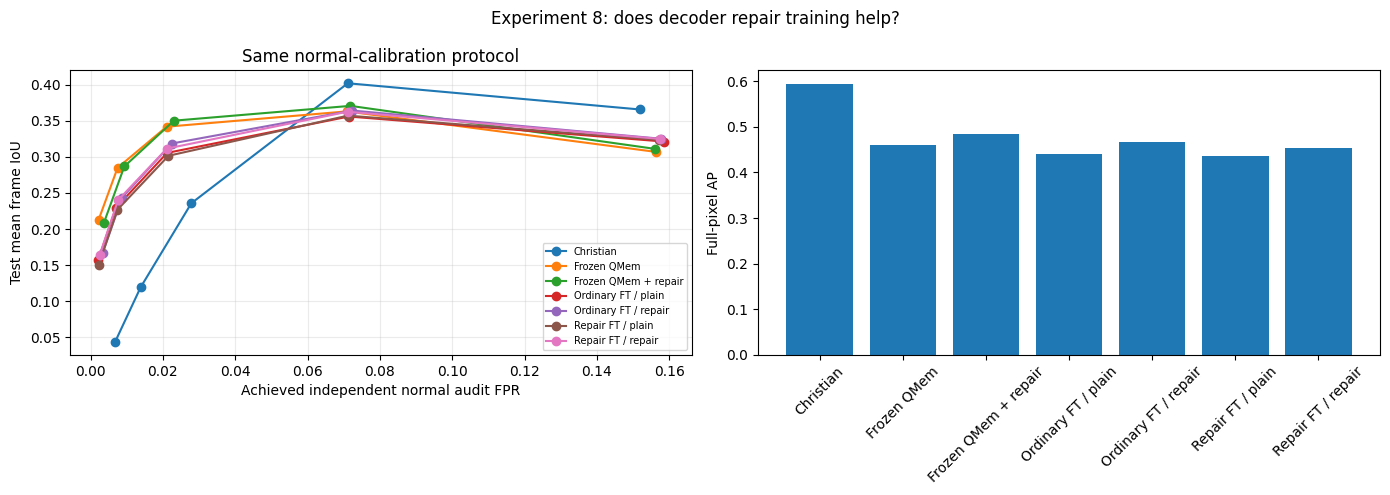

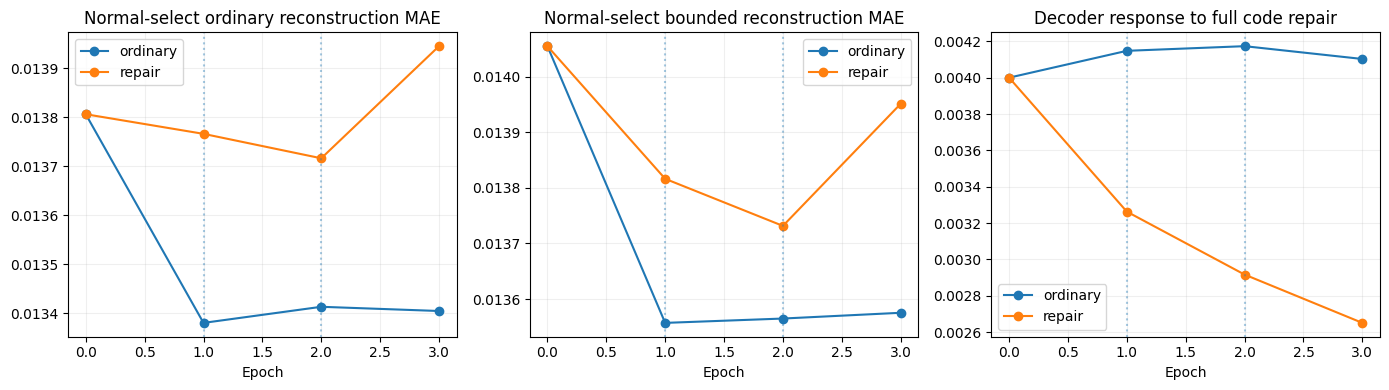

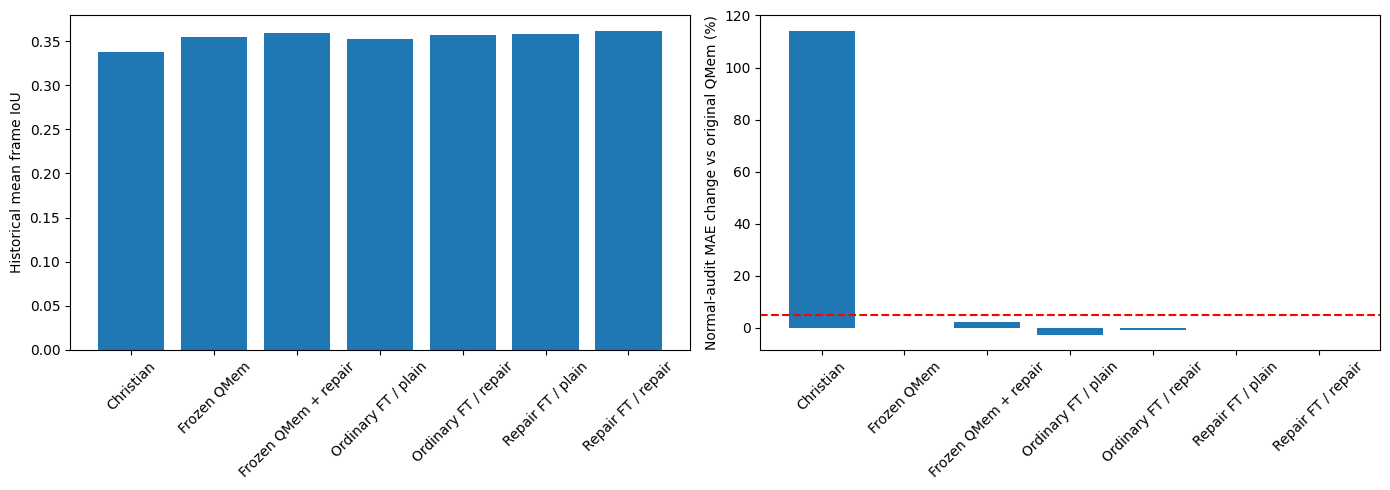

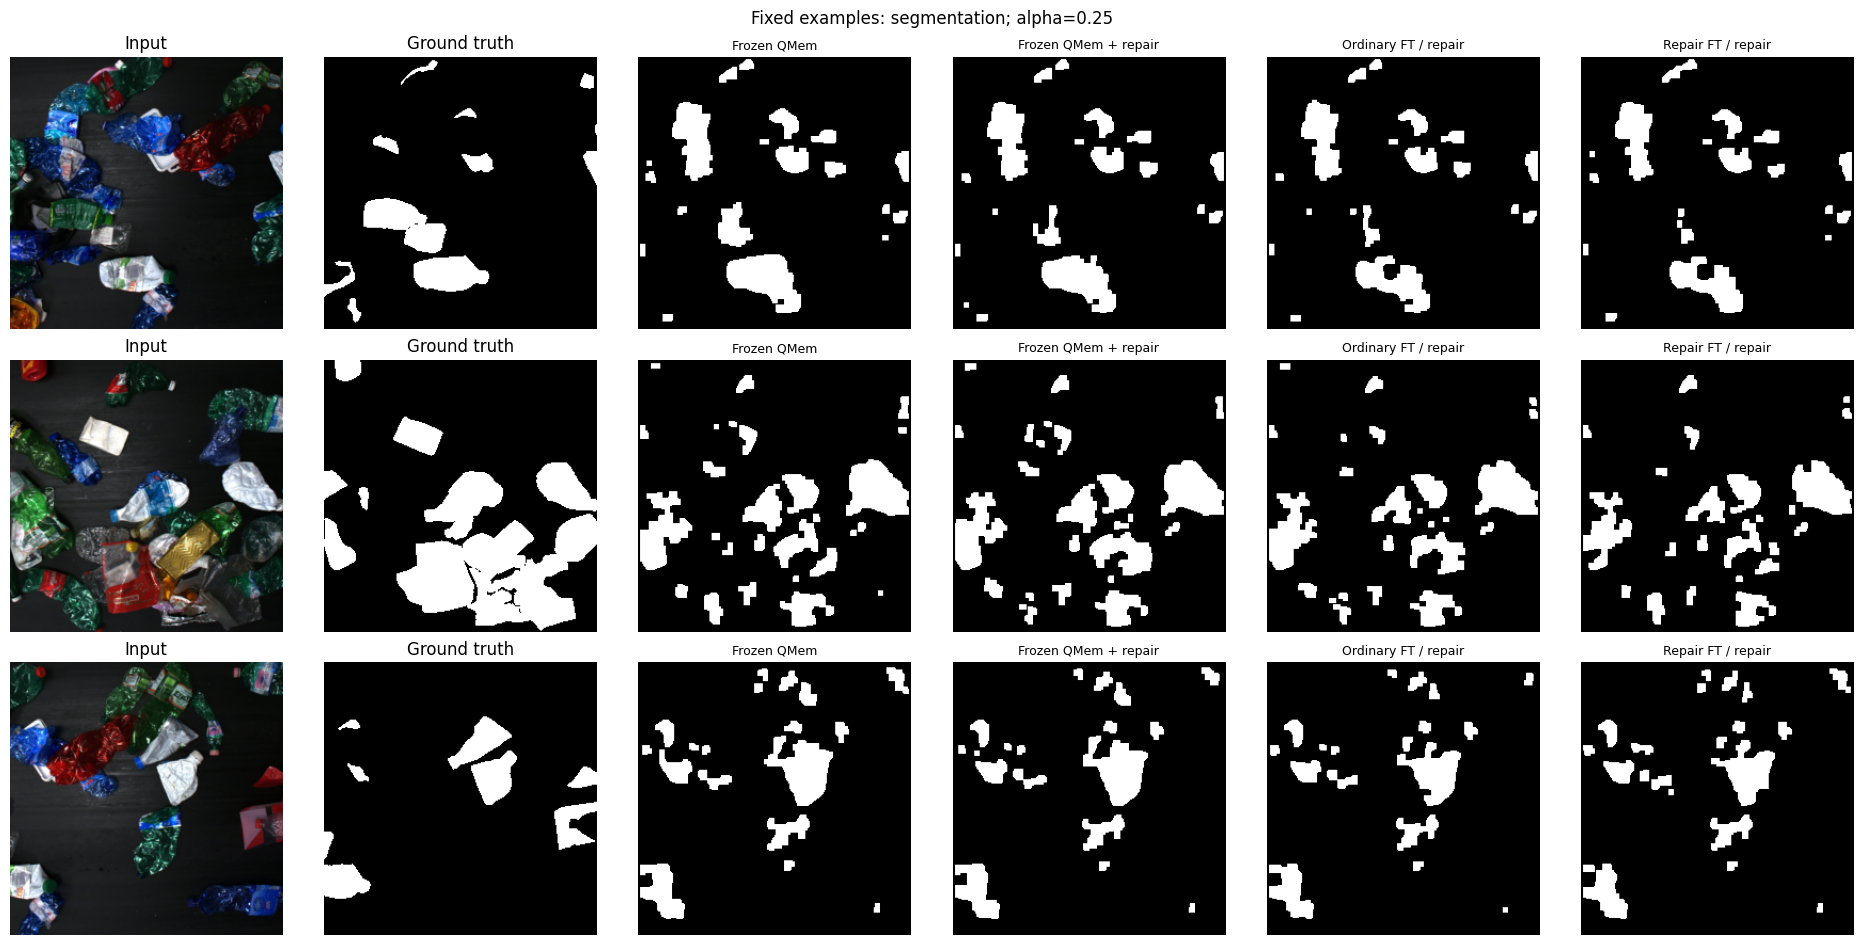

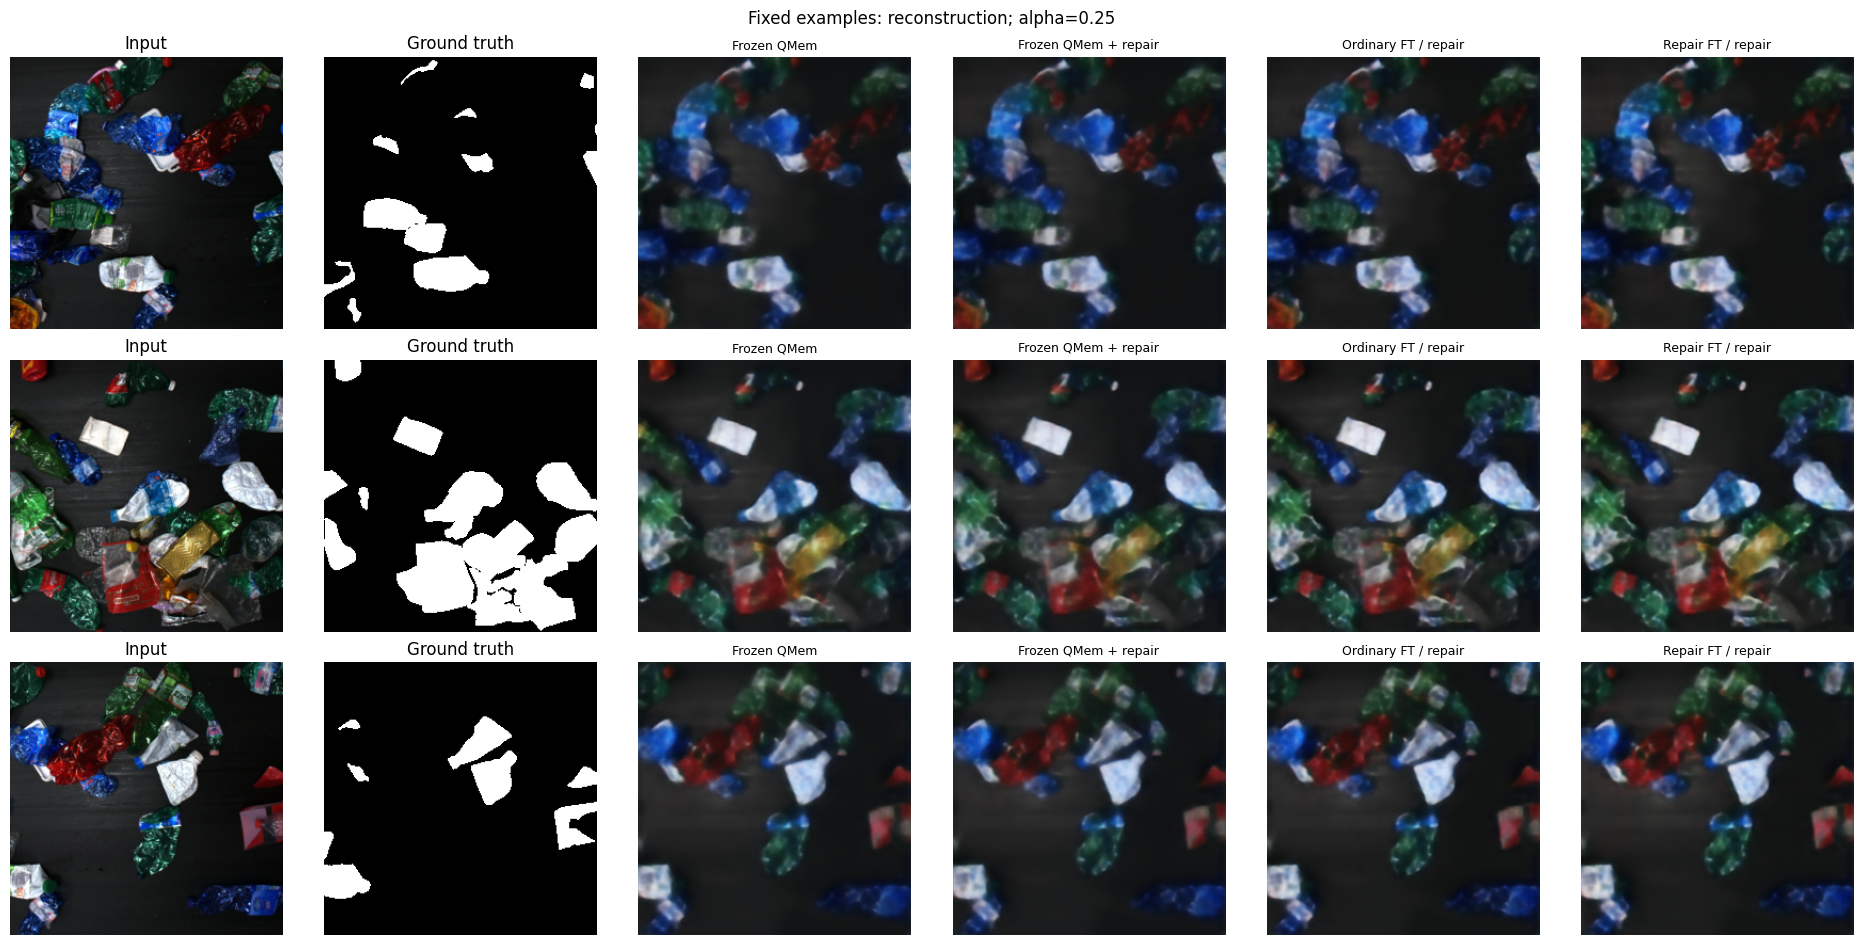

# Experiment 8 — decoder-only repair training

SMOKE=False. Full dataset run.
Only copied final decoders were optimized. Original encoders, top decoder, pre-quantization layer, codebooks and EMA stayed frozen. No QMem temporal loss was retrained.
Both arms used identical starting weights, image order, epochs, learning rate and optimizer. Ordinary arm: clean-code MSE. Repair arm: normalized clean + 0.5 * repaired-code MSE.
Inference alpha=0.25 fixed from Experiment 7; no alpha or lambda search. Selected epochs: {'ordinary': 1, 'repair': 2}.
Both arms use the same NORMAL-only checkpoint rule. Epoch zero can win; do not describe epoch-zero selection as evidence of beneficial fine-tuning.

## Main comparisons
```
                  stream  pixel_auroc  pixel_ap  historical_iou  primary_iou  normal_audit_fpr  test_normal_pixel_fpr  test_anomaly_pixel_recall  relative_mae_increase  within_budget
christian_reconstruction     0.848375  0.594226        0.337823     0.235794          0.027868    

/kaggle/working/qmem_experiment8/20260921_202543_2328f4/qmem_experiment8_report.zip

/kaggle/working/qmem_experiment8/20260921_202543_2328f4/qmem_experiment8_decoders.zip

In [8]:
# Block 8: paired comparisons, training diagnostics and compact reporting.
CONTRASTS=[('repair_bounded','ordinary_bounded'),('repair_bounded','qmem_bounded_repair'),('ordinary_bounded','qmem_bounded_repair'),('repair_plain','ordinary_plain'),('repair_bounded','repair_plain')]
def clustered_delta(df,first,second,column,keys):
    a=df[df.stream==first][keys+[column]].rename(columns={column:'first_value'})
    b=df[df.stream==second][keys+[column]].rename(columns={column:'second_value'})
    joined=a.merge(b,on=keys,validate='one_to_one')
    assert len(joined)==len(a)==len(b),'Pairing mismatch.'
    joined=joined.dropna(subset=['first_value','second_value'])
    joined['delta']=joined.first_value-joined.second_value
    grouped=joined.groupby('video').delta.agg(['sum','count'])
    if grouped.empty:return dict(videos=0,delta=np.nan,ci95_low=np.nan,ci95_high=np.nan)
    sums=grouped['sum'].to_numpy();counts=grouped['count'].to_numpy()
    rng=np.random.default_rng(SEED+901)
    samples=rng.integers(0,len(sums),size=(BOOTSTRAP_REPEATS,len(sums)))
    boot=sums[samples].sum(1)/counts[samples].sum(1)
    lo,hi=np.quantile(boot,[0.025,0.975])
    return dict(videos=len(sums),delta=float(sums.sum()/counts.sum()),ci95_low=float(lo),ci95_high=float(hi))


paired=[];frame_table=pd.DataFrame(frame_rows)
for mode in ('raw','post'):
    for f in FPR_TARGETS:
        df=frame_table[(frame_table['mode']==mode)&(frame_table.target_fpr==f)]
        for first,second in CONTRASTS:
            paired.append(dict(first=first,second=second,mode=mode,target_fpr=f,
                metric='mean_frame_iou',**clustered_delta(df,first,second,'iou',['video','relative'])))
pd.DataFrame(paired).to_csv(RUN_DIR/'paired_iou_contrasts.csv',index=False)
paired_rank=[];video_table=pd.DataFrame(video_rows)
for metric in ('pixel_ap','pixel_auroc'):
    for first,second in CONTRASTS:
        paired_rank.append(dict(first=first,second=second,metric='equal_video_mean_'+metric,
           **clustered_delta(video_table,first,second,metric,['video'])))
pd.DataFrame(paired_rank).to_csv(RUN_DIR/'paired_video_ranking.csv',index=False)
print('Paired contrasts; positive means the first method improved IoU:')
print(pd.DataFrame(paired).query("mode=='post' and target_fpr==@PRIMARY_FPR").to_string(index=False))

historical_pairs=[]
for first,second in CONTRASTS:
    d=pd.DataFrame(legacy_frame_rows);d=d[d['mode']=='post']
    historical_pairs.append(dict(first=first,second=second,protocol='legacy_all_val_tukey',
        **clustered_delta(d,first,second,'iou',['video','relative'])))
pd.DataFrame(historical_pairs).to_csv(RUN_DIR/'paired_historical_repair.csv',index=False)
print('Secondary historical reconstruction contrasts:')
print(pd.DataFrame(historical_pairs).to_string(index=False))

labels={'christian_reconstruction':'Christian','qmem_reconstruction':'Frozen QMem','qmem_bounded_repair':'Frozen QMem + repair','ordinary_plain':'Ordinary FT / plain','ordinary_bounded':'Ordinary FT / repair','repair_plain':'Repair FT / plain','repair_bounded':'Repair FT / repair'}
curve_table=pd.DataFrame(curve_rows);rank_table=pd.DataFrame(ranking_rows)
fig,ax=plt.subplots(1,2,figsize=(14,5))
for stream in STREAMS:
    d=curve_table[(curve_table.stream==stream)&(curve_table['mode']=='post')].sort_values('normal_audit_fpr')
    ax[0].plot(d.normal_audit_fpr,d.mean_frame_iou,'o-',label=labels[stream])
ax[0].set(xlabel='Achieved independent normal audit FPR',ylabel='Test mean frame IoU',title='Same normal-calibration protocol');ax[0].legend(fontsize=7);ax[0].grid(alpha=.25)
ax[1].bar([labels[s] for s in rank_table.stream],rank_table.pixel_ap);ax[1].set(ylabel='Full-pixel AP');ax[1].tick_params(axis='x',labelrotation=45)
fig.suptitle('SMOKE ONLY' if SMOKE else 'Experiment 8: does decoder repair training help?');fig.tight_layout();fig.savefig(RUN_DIR/'detection_comparison.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
mon=pd.DataFrame(monitor_rows)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for arm in ARMS:
    d=mon[mon.arm==arm]
    for ax,key in zip(axes,['plain_mae','bounded_mae','repair_change_mae']):
        ax.plot(d.epoch,d[key],'o-',label=arm);ax.axvline(selected_epochs[arm],linestyle=':',alpha=.4)
for ax,title in zip(axes,['Normal-select ordinary reconstruction MAE','Normal-select bounded reconstruction MAE','Decoder response to full code repair']):
    ax.set(xlabel='Epoch',title=title);ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(RUN_DIR/'training_diagnostics.png',dpi=150);plt.show();plt.close(fig)
legacy=pd.DataFrame(legacy_rows);hist=legacy[legacy['mode']=='post']
primary=curve_table[(curve_table['mode']=='post')&(curve_table.target_fpr==PRIMARY_FPR)]
comparison=rank_table.merge(hist[['stream','mean_frame_iou']].rename(columns={'mean_frame_iou':'historical_iou'}),on='stream').merge(primary[['stream','mean_frame_iou','normal_audit_fpr','test_normal_pixel_fpr','test_anomaly_pixel_recall']].rename(columns={'mean_frame_iou':'primary_iou'}),on='stream')
comparison=comparison.merge(damage_summary[damage_summary.split=='audit'][['stream','relative_mae_increase','within_budget']],on='stream');comparison.to_csv(RUN_DIR/'comparison_summary.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].bar([labels[s] for s in comparison.stream],comparison.historical_iou);axes[0].set(ylabel='Historical mean frame IoU')
axes[1].bar([labels[s] for s in comparison.stream],100*comparison.relative_mae_increase);axes[1].axhline(100*NORMAL_MAE_BUDGET,color='red',linestyle='--');axes[1].set(ylabel='Normal-audit MAE change vs original QMem (%)')
for ax in axes:ax.tick_params(axis='x',labelrotation=45)
fig.tight_layout();fig.savefig(RUN_DIR/'historical_and_damage.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
chosen=np.unique(np.linspace(0,len(splits['test'])-1,min(3,len(splits['test'])),dtype=int))
show_streams=('qmem_reconstruction','qmem_bounded_repair','ordinary_bounded','repair_bounded')
for kind in ('segmentation','reconstruction'):
    fig,axes=plt.subplots(len(chosen),len(show_streams)+2,figsize=(19,3.2*len(chosen)),squeeze=False)
    for row,i in enumerate(chosen):
        axes[row,0].imshow(load_x(splits['test'][i]['path']).permute(1,2,0));axes[row,0].set_title('Input')
        axes[row,1].imshow(gt[i],cmap='gray',vmin=0,vmax=1);axes[row,1].set_title('Ground truth')
        for col,stream in enumerate(show_streams,2):
            if kind=='segmentation':
                a=np.load(map_path(stream,'test'),mmap_mode='r');im=postprocess(a[i]>thresholds[stream][str(VISUAL_FPR)])
                axes[row,col].imshow(im,cmap='gray',vmin=0,vmax=1)
            else:axes[row,col].imshow(np.load(CACHE_DIR/f'example_{i}_{stream}.npy'))
            axes[row,col].set_title(labels[stream],fontsize=9)
        for ax in axes[row]:ax.axis('off')
    fig.suptitle(f'Fixed examples: {kind}; alpha={ALPHA}');fig.tight_layout();fig.savefig(RUN_DIR/(kind+'_examples.png'),dpi=140);plt.show();plt.close(fig)
primary_pairs=pd.DataFrame(paired).query("mode=='post' and target_fpr==@PRIMARY_FPR")
summary=f'''# Experiment 8 — decoder-only repair training

SMOKE={SMOKE}. {'IGNORE smoke performance values.' if SMOKE else 'Full dataset run.'}
Only copied final decoders were optimized. Original encoders, top decoder, pre-quantization layer, codebooks and EMA stayed frozen. No QMem temporal loss was retrained.
Both arms used identical starting weights, image order, epochs, learning rate and optimizer. Ordinary arm: clean-code MSE. Repair arm: normalized clean + {REPAIR_LAMBDA} * repaired-code MSE.
Inference alpha={ALPHA} fixed from Experiment 7; no alpha or lambda search. Selected epochs: {selected_epochs}.
Both arms use the same NORMAL-only checkpoint rule. Epoch zero can win; do not describe epoch-zero selection as evidence of beneficial fine-tuning.

## Main comparisons
```
{comparison.to_string(index=False)}
```

## Paired IoU differences at target calibration FPR {PRIMARY_FPR}
```
{primary_pairs.to_string(index=False)}
```

The causal control is repair_bounded versus ordinary_bounded. The practical control is repair_bounded versus qmem_bounded_repair (the existing frozen method). A gain over original un-repaired QMem alone does not establish value from repair training.
Read achieved audit FPR, AP, and normal damage alongside IoU. Equal calibration targets do not guarantee equal false-alarm rates. Historical all-validation Tukey IoU is a separate secondary protocol.
Checkpoint selection rewards NORMAL reconstruction, not anomaly detection. Training may undo the useful inference effect. Read test_region_score_summary.csv and normal_repair_sensitivity.csv, plus the detection metrics, to distinguish improved normal reconstruction from erased anomaly separation.
Region scores are pixel-weighted, Gaussian-smoothed absolute RGB residuals; changes do not by themselves establish better classification.
This is a one-seed exploratory pilot on repeatedly inspected test videos. Video-bootstrap intervals do not correct experiment selection and do not measure training-seed variability. Ranking intervals concern equal-video metrics, not pooled AP.
Empty-union IoU=1. Audit does not trigger checkpoint reselection. Full three-epoch training budget is matched even when normal selection chooses different epochs.

Share qmem_experiment8_report.zip and the log. Keep qmem_experiment8_decoders.zip for inference with the original QMem checkpoint. No large score arrays are needed for first review.
Decision: retain training only if it adds useful detection performance beyond both controls with acceptable normal damage and false alarms. If ordinary fine-tuning explains the gain, do not attribute it to repair loss. If training fails, retain Experiment 7 and close this training branch.
'''
(RUN_DIR/'supervisor_summary.md').write_text(summary)
save_json(RUN_DIR/'runtime.json',dict(python=sys.version,torch=torch.__version__,numpy=np.__version__,device=str(DEVICE),cuda=torch.version.cuda,gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU'))
report_path=RUN_DIR/'qmem_experiment8_report.zip'
with zipfile.ZipFile(report_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RUN_DIR.iterdir()):
        if p.is_file() and p.suffix.lower() in {'.csv','.json','.txt','.md','.png'}:z.write(p,p.name)
model_zip=RUN_DIR/'qmem_experiment8_decoders.zip'
with zipfile.ZipFile(model_zip,'w',zipfile.ZIP_DEFLATED) as z:
    for name in ('unigram_counts.npz','repair_gate.json','selection.json','protocol.json','thresholds.json','legacy_tukey_thresholds.json'):z.write(RUN_DIR/name,name)
    for arm in ARMS:z.write(trained_dir/f'{arm}_best.pth',f'{arm}_best.pth')
del gt,y,a
if not SAVE_RAW_MAPS:
    for p in CACHE_DIR.glob('*.npy'):
        if not p.name.startswith('codes_'):p.unlink()
print(summary);print('REPORT:',report_path,'\nDECODERS:',model_zip)
try:
    from IPython.display import display,FileLink
    display(FileLink(str(report_path)));display(FileLink(str(model_zip)))
except ImportError:pass


## 9. Single-image inference helper

Defines predict_image for a demonstration in the current notebook session. It defaults to the established frozen bounded method; choose a trained stream explicitly only after evaluating the research results. Uses exactly the evaluation transform, score smoothing, calibrated threshold and morphology.

In [9]:
# Block 9: reusable single-image demo for the CURRENT notebook session.
# Default is the established frozen method, not the unconfirmed trained candidate.
@torch.no_grad()
def predict_image(image_path,method='qmem_bounded_repair',target_fpr=0.02):
    if method not in STREAMS:raise ValueError(f'Choose one of {STREAMS}')
    if str(target_fpr) not in thresholds[method]:raise ValueError(f'Choose one of {FPR_TARGETS}')
    x=load_x(image_path)[None].to(DEVICE)
    if method=='christian_reconstruction':
        m=load_model('christian');rec=expose(m,x)['recon'];del m
    else:
        o=expose(base,x);u,v,_=decoder_inputs(o['bottom_ids'],o['top_ids'])
        if method.startswith('qmem_'):
            a=o['recon'];b=torch.sigmoid(base.decoder_final(v))
            rec=a if method=='qmem_reconstruction' else blend(a,b)
        else:
            arm,mode=method.split('_');a,b=decode_pair(selected_decoders[arm],u,v)
            rec=a if mode=='plain' else blend(a,b)
    score=smooth_maps((x-rec).abs().mean(1).cpu().numpy())[0]
    return dict(reconstruction=rec[0].permute(1,2,0).cpu().numpy(),score=score,
                mask=postprocess(score>thresholds[method][str(target_fpr)]),method=method)

# Example after reviewing the results:
# result = predict_image('/kaggle/input/YOUR_DATA/images/before/VIDEO/IMAGE.png')
# plt.imshow(result['mask'], cmap='gray'); plt.show()
# The output mask is 256 x 256, matching the evaluation resolution.
print('Single-image demo ready: predict_image(path, method=..., target_fpr=0.02)')


Single-image demo ready: predict_image(path, method=..., target_fpr=0.02)


## Return these outputs

Send **qmem_experiment8_report.zip** and the complete notebook log. The compact report includes:

- comparison_summary.csv: IoU, AP/AUROC, achieved false alarms, recall and normal damage.
- training_log.csv, normal_epoch_monitor.csv and selection.json: training behaviour and selected epochs.
- training_checks.csv, frozen_checks.csv, loss_routing_checks.json and implementation_checks.json: whether the intended intervention was implemented.
- paired_iou_contrasts.csv and paired_historical_repair.csv: paired differences with video-bootstrap intervals.
- test_region_score_summary.csv and normal_repair_sensitivity.csv: whether reconstruction changes are useful or merely undone.
- historical_reproduction_check.csv: baseline reproducibility.
- supervisor_summary.md and PNG figures: compact interpretation and visual examples.

Keep **qmem_experiment8_decoders.zip** plus the original QMem checkpoint for reproduction. This archive contains the selected decoder weights, normal counts, gate, alpha and thresholds. To restore later, rerun setup/architecture and normal prior blocks, load each `decoder_state_dict` into a copy of `base.decoder_final`, and use the stored gate/threshold/alpha configuration; no retraining is required. The current-session demo is in Block 9. Original model weights are not duplicated inside the decoder ZIP. Last-epoch optimizer snapshots remain under trained_decoders in the full Kaggle output.

No large .npy score files are required for the first review. The notebook deletes them after producing reports unless SAVE_RAW_MAPS=True.

## How the final system is shaping up

The established candidate is: **QMem-trained VQ-VAE-2 → normal-frequency bottom-code repair → original and repaired decoding → bounded reconstruction → residual map → calibrated anomaly mask**. QMem temporal information is used in the original training; this inference path takes one image.

This experiment changes only the decoder used in that system. A trained decoder belongs in the final system only if it contributes beyond ordinary extra training AND the established frozen method. If ordinary fine-tuning explains the gain, attribute it accordingly. If the new decoder harms anomaly separation, retain the successful inference-only method. No new encoder training, reset or context predictor is automatically triggered.

Remaining paper confirmation is separate from this experiment: assess repair on Christian for the missing interaction comparison, use untouched videos if available, and assess original QMem training variability if resources permit. These are not implemented or claimed by this notebook. Begin methods/experimental-protocol writing now; finalize the selected method after this bounded training test. Repeated use of the current test set makes these results exploratory even when paired intervals exclude zero.
